
# Iris Flower Classification

## Project Objective
The objective of this project is to build a machine learning classification model that predicts the species of an iris flower based on its physical measurements.

The dataset contains three species: Iris Setosa, Iris Versicolor, and Iris Virginica. Each flower is described using four features: sepal length, sepal width, petal length, and petal width.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Workflow

1. Introduce the project and load the Iris dataset.
2. Perform exploratory data analysis (EDA) and discuss feature selection.
3. Prepare the data and split it into training and testing sets.
4. Train Logistic Regression and K-Nearest Neighbors (KNN) classification models.
5. Evaluate both models using accuracy, confusion matrices, precision, recall, and F1-scores.
6. Compare model performance, identify the better-performing model based on the results, and summarise the findings.


## Step 1: Introduction and Data Loading

In this step, we will introduce the Iris Flower Classification project and load the built-in Iris dataset from Scikit-learn. We will import the libraries required for data handling, visualisation, and machine learning, and inspect the dataset's structure, columns, and initial observations.

This will help us understand the data we are working with before beginning exploratory data analysis.


In [1]:
# Import libraries for data handling and visualisation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import the built-in Iris dataset
from sklearn.datasets import load_iris

# Import tools for splitting data and building classification models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Import tools for feature scaling and model pipelines
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Set the visual style for plots
sns.set_style("whitegrid")

print("All libraries imported successfully.")


All libraries imported successfully.


In [3]:
# Load the Iris dataset from scikit-learn
iris = load_iris()

# Create a DataFrame containing the four flower measurements
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the numerical species labels
df["species"] = iris.target

# Create a readable species name column
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset loaded successfully.")

display(df.head())

Dataset loaded successfully.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



## Step 2: Exploratory Data Analysis (EDA)

In this step, we will explore the Iris dataset to understand its structure, check for missing values, examine descriptive statistics, and study the distribution of the three flower species. We will use a pairplot and box plots to visualise relationships and differences between the four measurement features.

Based on these observations, we will discuss which features appear most useful for distinguishing the species and decide which features to retain for model training.


In [4]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the data types and non-null counts
print("\nDataset information:")
df.info()


Dataset shape: (150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species', 'species_name']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB


In [5]:
# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Calculate descriptive statistics for numerical columns
print("\nDescriptive statistics:")
display(df.describe())


Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [6]:
# Count the observations belonging to each species
species_counts = df["species_name"].value_counts()

print("Number of observations per species:")
display(species_counts)

Number of observations per species:


species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

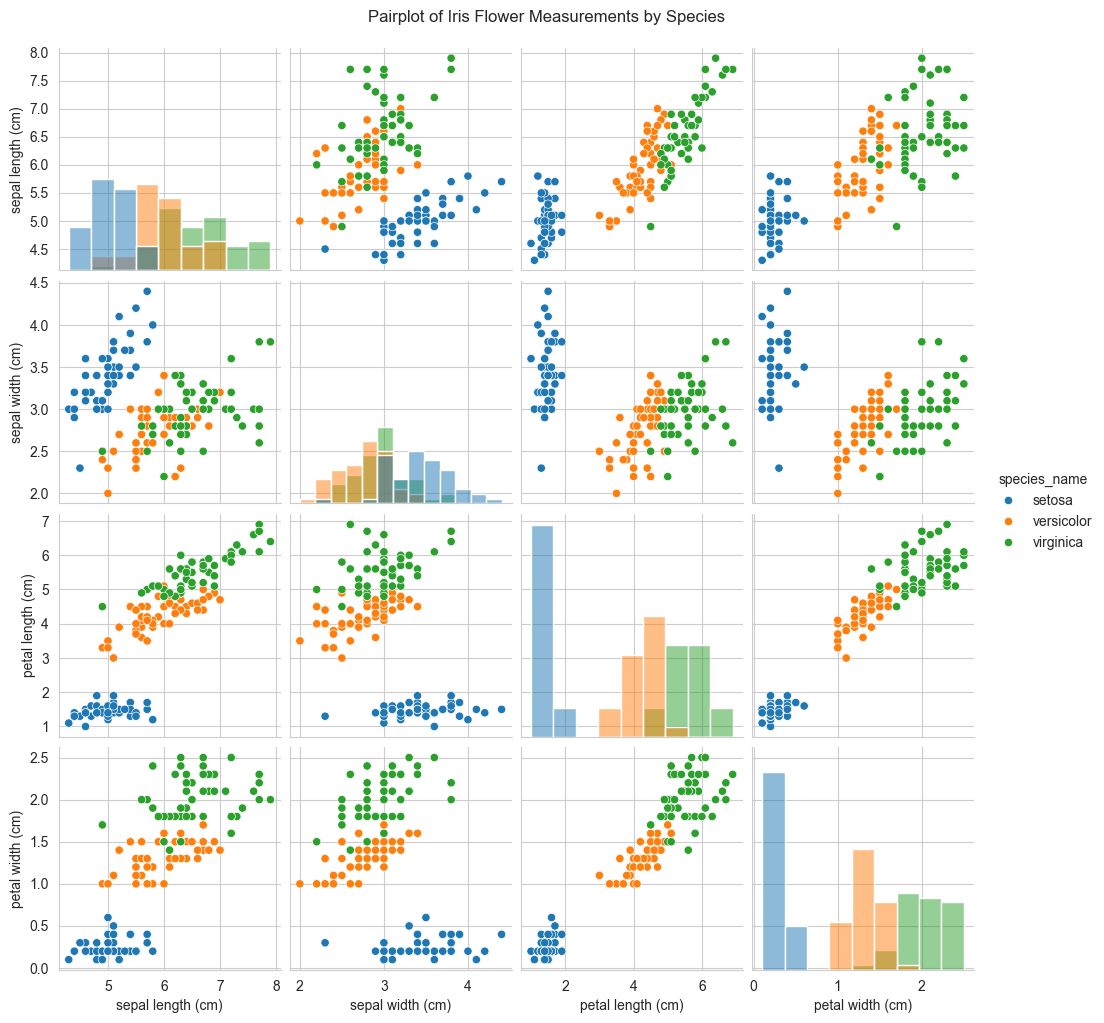

In [7]:
# Visualise pairwise relationships between the four measurements
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species_name",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Flower Measurements by Species", y=1.02)
plt.show()


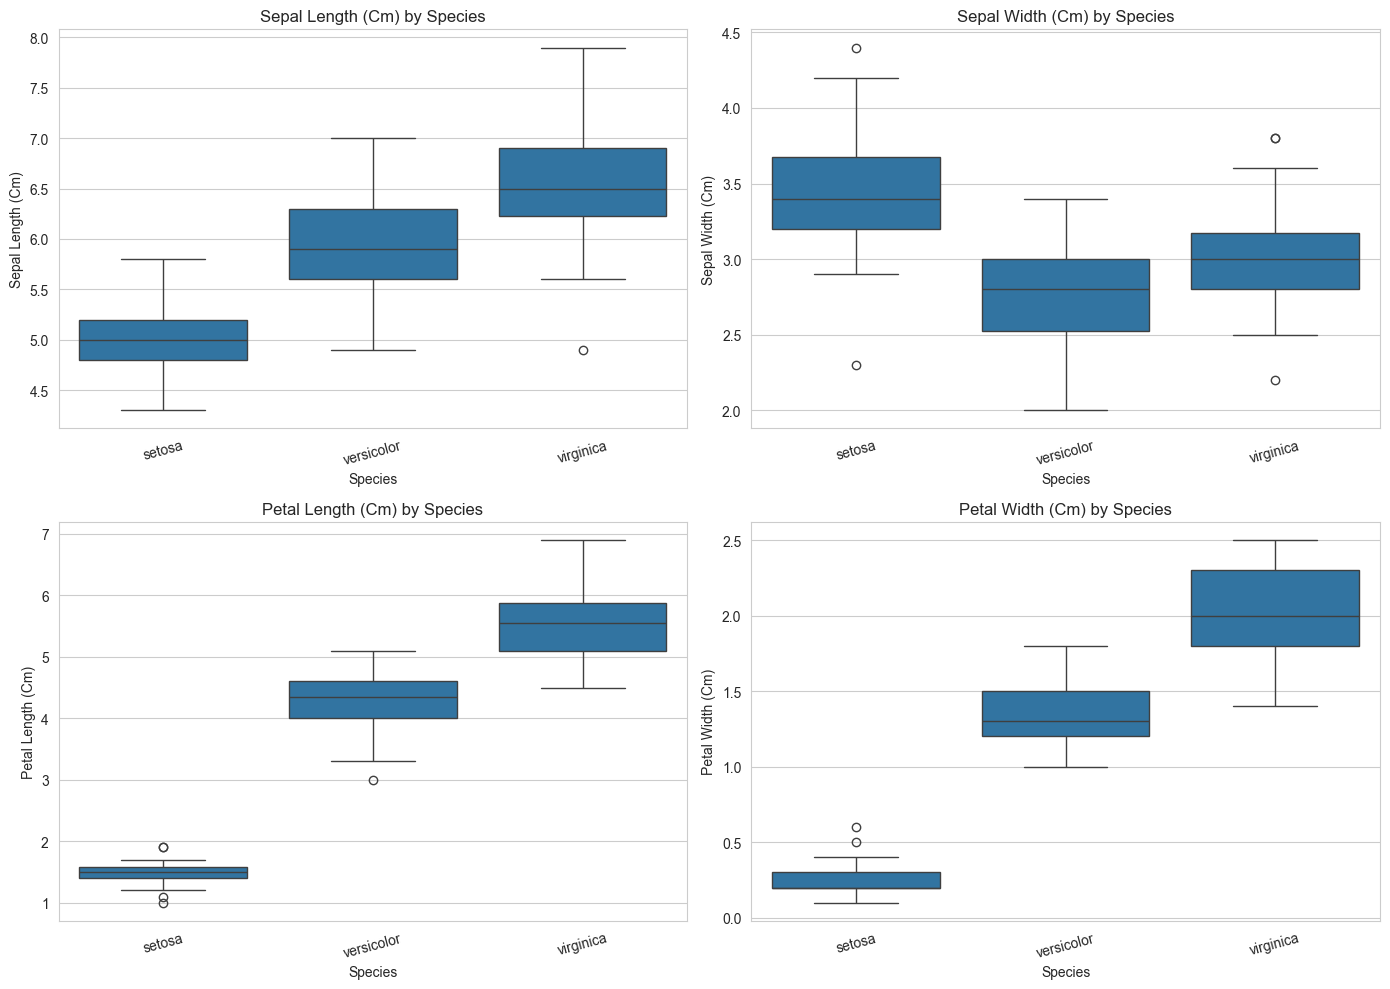

In [8]:
# List the four measurement features
features = iris.feature_names

# Create one box plot for each feature
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="species_name",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature.title()} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature.title())
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


## EDA Findings and Feature Selection

### Dataset Overview

The Iris dataset contains **150 rows and 6 columns**. Four columns represent flower measurements: sepal length, sepal width, petal length, and petal width. The remaining two columns represent the species using numerical labels and readable species names.

The four measurement columns contain floating-point values, while the `species` column contains integer labels and `species_name` contains text. The dataset has **no missing values**, so no missing-value treatment is required. The descriptive statistics show that the measurements vary across the dataset, providing useful information for distinguishing between flower species.

### Species Distribution

The dataset contains three species: Setosa, Versicolor, and Virginica. Each species has **50 observations**, making the dataset evenly distributed across the three classes. This balanced distribution means that no species is represented more frequently than the others.

### Visualisation Findings

The pairplot helps compare the relationships between the four measurements and shows how the measurements vary across species. Setosa appears clearly separated from the other two species, particularly when petal length and petal width are considered. Versicolor and Virginica show some overlap, although their petal measurements generally differ.

The box plots provide another way to compare the distributions of each measurement across the three species. The petal measurements show clearer differences between species than the sepal measurements. In comparison, sepal length and sepal width show greater overlap, making them less effective on their own for distinguishing all three species.

### Feature Selection Discussion

Based on the pairplot and box plots, **petal length and petal width appear to be the most useful features** for classifying Iris species because they show clearer separation between the classes. Sepal length and sepal width may still provide additional information when used alongside the petal measurements.

Therefore, all four measurement features will initially be retained for model training. Their usefulness can be assessed through the performance of the classification models rather than removing features based only on visual inspection.


## Step 3: Data Preparation

Before training the models, we need to separate the input features from the target variable.

- **Features (X):** The four flower measurements used to predict the species.
- **Target (y):** The species label that the model will learn to predict.

We will divide the dataset into training data and testing data using an 80:20 split. The models will learn from 80% of the observations and will be evaluated on the remaining 20%.

We will use stratified sampling to preserve the proportion of each species in both sets. A fixed random state will make the split reproducible.


In [9]:
# Select the four flower measurements as input features
X = df[iris.feature_names]

# Select the numerical species labels as the target
y = df["species"]

# Display the dimensions of the features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (150, 4)
Target shape: (150,)


In [10]:

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dimensions of each set
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (120, 4)
Testing features shape: (30, 4)
Training target shape: (120,)
Testing target shape: (30,)


In [11]:

# Check the distribution of species in the training data
print("Training set species counts:")
print(y_train.map(dict(enumerate(iris.target_names))).value_counts().sort_index())

# Check the distribution of species in the testing data
print("\nTesting set species counts:")
print(y_test.map(dict(enumerate(iris.target_names))).value_counts().sort_index())


Training set species counts:
species
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64

Testing set species counts:
species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64



## Step 4: Model Training

We will train two classification models: Logistic Regression and K-Nearest Neighbors (KNN).

Feature scaling will be applied using `StandardScaler`, which standardises the measurements so that features with larger numerical values do not dominate those with smaller values. We will use a pipeline to ensure that scaling is fitted only on the training data.

Both models will be trained using the same training set and evaluated on the same test set in the next step. This will allow us to compare their results fairly.



### Model 1: Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification. It learns patterns in the input measurements and uses them to estimate the probability that a flower belongs to each species.

We will use `StandardScaler` before Logistic Regression and increase the maximum number of iterations to give the model sufficient opportunity to converge.


In [12]:

# Create a pipeline that scales the features and trains Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train Logistic Regression using the training data
logistic_model.fit(X_train, y_train)

# Confirm that the model has been trained
print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.



### Model 2: K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised classification algorithm that compares a new observation with nearby observations in the training data. It predicts the class based on the classes of its nearest neighbors.

We will use 5 neighbors (`n_neighbors=5`) as our initial setting. Since KNN relies on distances between observations, we will standardise the features before training the model.


In [13]:

# Create a pipeline that scales the features and trains KNN
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train KNN using the training data
knn_model.fit(X_train, y_train)

# Confirm that the model has been trained
print("K-Nearest Neighbors model trained successfully.")


K-Nearest Neighbors model trained successfully.


In [14]:

# Confirm that both models are ready for evaluation
print("Models trained:")
print("1. Logistic Regression")
print("2. K-Nearest Neighbors (KNN)")


Models trained:
1. Logistic Regression
2. K-Nearest Neighbors (KNN)



## Step 5: Model Evaluation

After training the models, we need to evaluate their performance using the testing dataset. The models will make predictions on the test features, and these predictions will be compared with the actual species labels.

We will use the following evaluation metrics:

- **Accuracy:** The proportion of all predictions that are correct.
- **Confusion Matrix:** Shows the number of correct and incorrect predictions for each species.
- **Precision:** Measures how many predictions for a species were correct.
- **Recall:** Measures how many actual observations of a species were correctly identified.
- **F1-Score:** Combines precision and recall into a single measure.

We will calculate these metrics for both Logistic Regression and K-Nearest Neighbors (KNN).


In [15]:

# Generate predictions using Logistic Regression
y_pred_logistic = logistic_model.predict(X_test)

# Generate predictions using K-Nearest Neighbors
y_pred_knn = knn_model.predict(X_test)

# Confirm that predictions have been generated
print("Predictions generated successfully.")

# Display the first ten actual and predicted labels
print("\nFirst ten actual species labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst ten Logistic Regression predictions:")
print(y_pred_logistic[:10].tolist())

print("\nFirst ten KNN predictions:")
print(y_pred_knn[:10].tolist())


Predictions generated successfully.

First ten actual species labels:
[0, 2, 1, 1, 0, 1, 0, 0, 2, 1]

First ten Logistic Regression predictions:
[0, 2, 1, 1, 0, 1, 0, 0, 2, 1]

First ten KNN predictions:
[0, 2, 1, 1, 0, 1, 0, 0, 2, 1]


In [16]:

# Calculate the accuracy of Logistic Regression
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

# Calculate the accuracy of KNN
accuracy_knn = accuracy_score(y_test, y_pred_knn)

# Display both accuracy scores as percentages
print(f"Logistic Regression Accuracy: {accuracy_logistic:.2%}")
print(f"KNN Accuracy: {accuracy_knn:.2%}")


Logistic Regression Accuracy: 93.33%
KNN Accuracy: 93.33%


In [17]:

# Define readable names for the three species
species_names = list(iris.target_names)

# Calculate the confusion matrix for Logistic Regression
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=[0, 1, 2]
)

# Calculate the confusion matrix for KNN
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=[0, 1, 2]
)

# Display the confusion matrix for Logistic Regression
print("Logistic Regression Confusion Matrix:")
display(pd.DataFrame(
    cm_logistic,
    index=[f"Actual {name}" for name in species_names],
    columns=[f"Predicted {name}" for name in species_names]
))

# Display the confusion matrix for KNN
print("KNN Confusion Matrix:")
display(pd.DataFrame(
    cm_knn,
    index=[f"Actual {name}" for name in species_names],
    columns=[f"Predicted {name}" for name in species_names]
))


Logistic Regression Confusion Matrix:


,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,9,1
Actual virginica,0,1,9


KNN Confusion Matrix:


,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,10,0
Actual virginica,0,2,8


In [18]:

# Generate the classification report for Logistic Regression
print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    labels=[0, 1, 2],
    target_names=species_names,
    zero_division=0
))

# Generate the classification report for KNN
print("KNN Classification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=[0, 1, 2],
    target_names=species_names,
    zero_division=0
))


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30




### Evaluation Observations

The accuracy scores show the proportion of test observations classified correctly by each model. The confusion matrices help identify which species, if any, were misclassified. The classification reports provide additional insight into each model's precision, recall, and F1-score for individual species.

The final comparison will consider all these metrics rather than relying on accuracy alone.



## Step 6: Model Comparison and Conclusion

In this step, we will compare Logistic Regression and K-Nearest Neighbors using their accuracy, precision, recall, F1-score, and confusion matrices. We will then identify the better-performing model based on the observed results.

Since both models achieved the same accuracy, we will also consider the types of classification errors each model made before drawing a conclusion.


In [19]:

# Create a dictionary containing the evaluation results of both models
model_results = {
    "Model": ["Logistic Regression", "K-Nearest Neighbors"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_knn)
    ],
    "Macro Precision": [
        # Calculate macro-average precision for Logistic Regression
        classification_report(
            y_test, y_pred_logistic,
            output_dict=True, zero_division=0
        )["macro avg"]["precision"],

        # Calculate macro-average precision for KNN
        classification_report(
            y_test, y_pred_knn,
            output_dict=True, zero_division=0
        )["macro avg"]["precision"]
    ],
    "Macro Recall": [
        # Calculate macro-average recall for Logistic Regression
        classification_report(
            y_test, y_pred_logistic,
            output_dict=True, zero_division=0
        )["macro avg"]["recall"],

        # Calculate macro-average recall for KNN
        classification_report(
            y_test, y_pred_knn,
            output_dict=True, zero_division=0
        )["macro avg"]["recall"]
    ],
    "Macro F1-Score": [
        # Calculate macro-average F1-score for Logistic Regression
        classification_report(
            y_test, y_pred_logistic,
            output_dict=True, zero_division=0
        )["macro avg"]["f1-score"],

        # Calculate macro-average F1-score for KNN
        classification_report(
            y_test, y_pred_knn,
            output_dict=True, zero_division=0
        )["macro avg"]["f1-score"]
    ]
}

# Convert the results into a DataFrame
comparison_df = pd.DataFrame(model_results)

# Display the results rounded to four decimal places
display(comparison_df.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,K-Nearest Neighbors,0.9333,0.9444,0.9333,0.9327


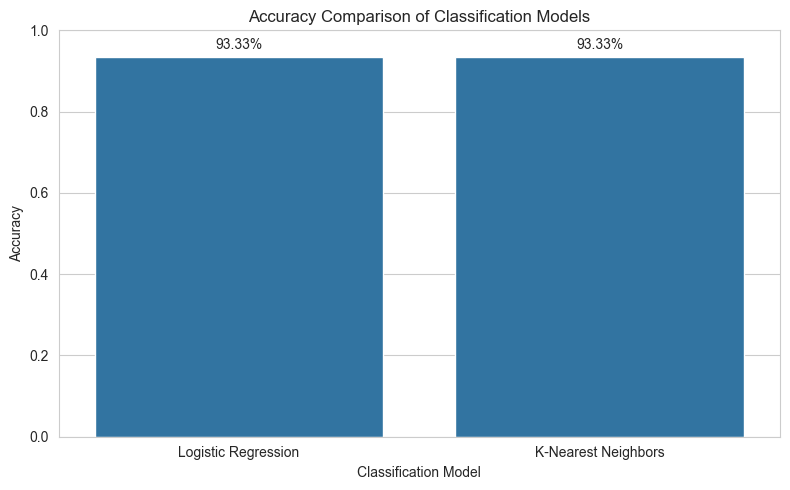

In [20]:

# Plot the accuracy of both classification models
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

# Add percentage labels above the bars
for index, accuracy in enumerate(comparison_df["Accuracy"]):
    plt.text(
        index,
        accuracy + 0.02,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()



### Model Comparison

Both Logistic Regression and K-Nearest Neighbors achieved an accuracy of 93.33% on the test dataset, correctly classifying 28 out of 30 observations.

Both models classified all Setosa observations correctly. Logistic Regression correctly classified 9 out of 10 Versicolor observations and 9 out of 10 Virginica observations. KNN correctly classified all 10 Versicolor observations but classified 2 Virginica observations as Versicolor.

KNN achieved higher precision for Virginica but lower recall for that species. Logistic Regression had a more balanced recall across Versicolor and Virginica. These differences demonstrate that models with equal accuracy can still behave differently when predicting individual classes.

### Conclusion

Both Logistic Regression and K-Nearest Neighbors achieved an accuracy of 93.33% on the test dataset. KNN achieved slightly higher macro precision, while Logistic Regression achieved a marginally higher macro F1-score. Both models had the same macro recall.

Logistic Regression correctly classified 9 out of 10 Versicolor observations and 9 out of 10 Virginica observations, whereas KNN correctly classified all Versicolor observations but only 8 out of 10 Virginica observations. Therefore, Logistic Regression is selected as the preferred model for this project because it demonstrated more balanced recall across the three species.

However, the overall performance of the two models is very similar, and the small differences in their metrics do not establish a definitive winner. Further evaluation using cross-validation could help determine which model generalises more consistently to unseen data.



### Limitations and Future Improvements

This project uses the built-in Iris dataset, which is small and relatively clean. The models were evaluated on a single train-test split, so their results may vary with a different split.

Future improvements could include using cross-validation, experimenting with different KNN neighbor counts, and testing additional classification algorithms. These steps could provide a more robust comparison of model performance.
